In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D9/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'UniqueMappingClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'UniqueMappingClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'UniqueMappingClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
#df_scm = pd.read_csv(main_dir + 'UniqueMappingClustering_scm.csv')
#df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard]#, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else {}
)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,clustering_threshold,matcher,matching_thr,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with UniqueMappingClustering,2473,0.30,cosine,0.05,88.96,95.49,92.11,2200,273,61418,104,cosine,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
1,Clustering with UniqueMappingClustering,2452,0.40,cosine,0.05,89.72,95.49,92.51,2200,252,61418,104,cosine,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
2,Clustering with UniqueMappingClustering,2476,0.20,cosine,0.05,88.85,95.49,92.05,2200,276,61418,104,cosine,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
3,Clustering with UniqueMappingClustering,2425,0.50,cosine,0.05,90.72,95.49,93.04,2200,225,61418,104,cosine,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
4,Clustering with UniqueMappingClustering,2387,0.60,cosine,0.05,92.08,95.40,93.71,2198,189,61416,106,cosine,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16711,Clustering with UniqueMappingClustering,2358,0.55,jaccard,92.92,95.10,93.99,2191.00,167,61409,113,"{'attributes': ['title'], 'size': 1024, 'offse...",jaccard,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16712,Clustering with UniqueMappingClustering,2277,0.65,jaccard,94.16,93.06,93.60,2144.00,133,61362,160,"{'attributes': ['title'], 'size': 1024, 'offse...",jaccard,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16713,Clustering with UniqueMappingClustering,2157,0.75,jaccard,95.09,89.02,91.95,2051.00,106,61269,253,"{'attributes': ['title'], 'size': 1024, 'offse...",jaccard,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16714,Clustering with UniqueMappingClustering,1971,0.85,jaccard,95.89,82.03,88.42,1890.00,81,61108,414,"{'attributes': ['title'], 'size': 1024, 'offse...",jaccard,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
result['attributes'].value_counts()

attributes
[title]    16416
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0.0    16416
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    16416
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4.0    16416
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024.0    16416
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1.0     513
2.0     513
3.0     513
4.0     513
5.0     513
6.0     513
7.0     513
8.0     513
9.0     513
10.0    513
11.0    513
12.0    513
13.0    513
14.0    513
15.0    513
16.0    513
17.0    513
18.0    513
19.0    513
20.0    513
21.0    513
22.0    513
23.0    513
24.0    513
25.0    513
26.0    513
27.0    513
28.0    513
29.0    513
30.0    513
31.0    513
32.0    513
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,clustering_threshold,matcher,matching_thr,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
5,Clustering with UniqueMappingClustering,2333,0.7,cosine,0.05,93.53,94.70,94.11,2182,151,61400,122,cosine,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
5578,Clustering with UniqueMappingClustering,2316,0.7,dice,0.05,93.78,94.27,94.03,2172,144,61390,132,dice,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
11147,Clustering with UniqueMappingClustering,2344,0.5,jaccard,0.05,93.17,94.79,93.98,2184,160,61402,120,jaccard,[title],1024.0,0.0,1.0,salted_qgrams,,4.0
177,Clustering with UniqueMappingClustering,2334,0.7,cosine,0.05,93.62,94.84,94.22,2185,149,61403,119,cosine,[title],1024.0,0.0,2.0,salted_qgrams,,4.0
5748,Clustering with UniqueMappingClustering,2322,0.7,dice,0.05,93.80,94.53,94.16,2178,144,61396,126,dice,[title],1024.0,0.0,2.0,salted_qgrams,,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10710,Clustering with UniqueMappingClustering,2224,0.9,dice,0.05,93.97,90.71,92.31,2090,134,61308,214,dice,[title],1024.0,0.0,31.0,salted_qgrams,,4.0
16281,Clustering with UniqueMappingClustering,2253,0.8,jaccard,0.05,93.65,91.58,92.60,2110,143,61328,194,jaccard,[title],1024.0,0.0,31.0,salted_qgrams,,4.0
5309,Clustering with UniqueMappingClustering,2242,0.9,cosine,0.05,93.80,91.28,92.52,2103,139,61321,201,cosine,[title],1024.0,0.0,32.0,salted_qgrams,,4.0
10881,Clustering with UniqueMappingClustering,2236,0.9,dice,0.05,93.78,91.02,92.38,2097,139,61315,207,dice,[title],1024.0,0.0,32.0,salted_qgrams,,4.0


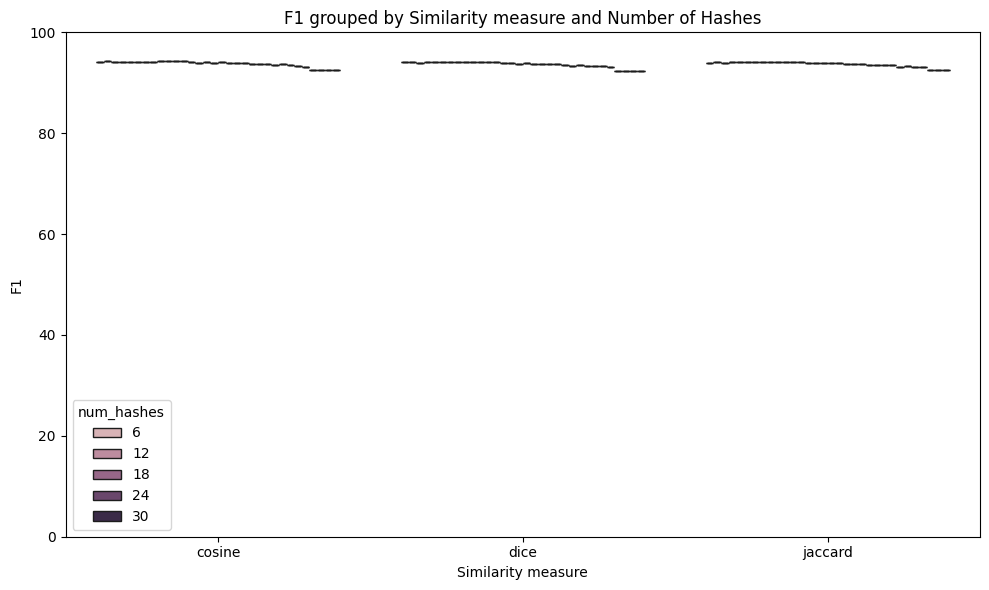

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1.0,Precision %,93.53
1,dice,1.0,Precision %,93.78
2,jaccard,1.0,Precision %,93.17
3,cosine,2.0,Precision %,93.62
4,dice,2.0,Precision %,93.80
...,...,...,...,...
283,dice,31.0,F1 %,92.31
284,jaccard,31.0,F1 %,92.60
285,cosine,32.0,F1 %,92.52
286,dice,32.0,F1 %,92.38


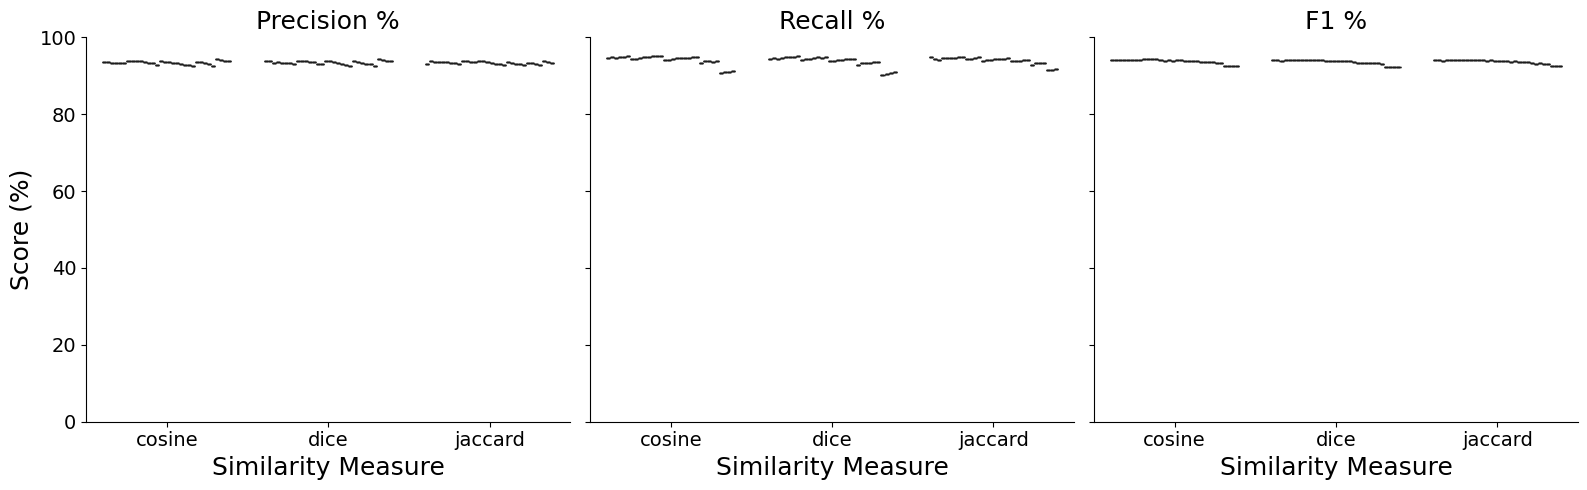

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

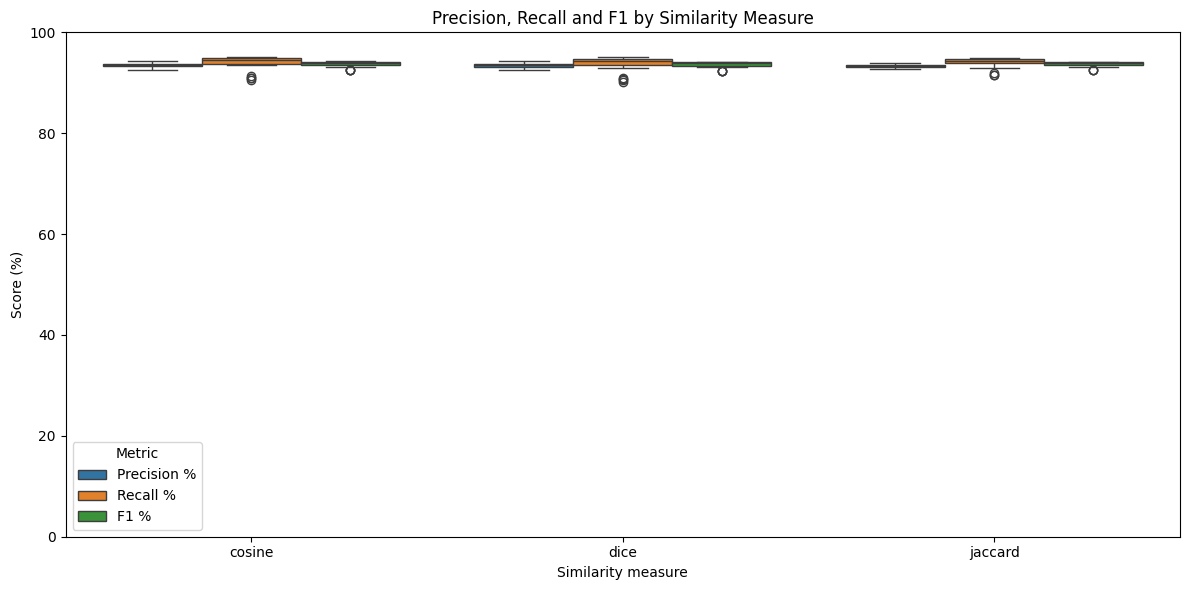

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()